# Análisis de Sentimiento en Tweets de Fútbol mediante Transfer Learning con BERT

### Laboratorio de LLMs: Fine-tuning y Transfer Learning

En este laboratorio se utilizará un modelo BERT preentrenado para clasificar
el sentimiento expresado en mensajes relacionados con partidos de fútbol.

Se aplicará Transfer Learning congelando las capas base de BERT mediante
`requires_grad = False`, de manera que durante el entrenamiento solamente
se actualicen los parámetros de la cabeza de clasificación.

## 0. Objetivo del laboratorio

El objetivo es construir un clasificador de sentimiento utilizando
`bert-base-multilingual-cased`.

El flujo del laboratorio será:

1. Cargar y explorar un dataset de tweets sobre fútbol.
2. Preparar las etiquetas y dividir los datos.
3. Tokenizar los textos utilizando el tokenizador de BERT.
4. Cargar BERT como modelo de clasificación.
5. Congelar las capas base del modelo.
6. Entrenar únicamente la cabeza de clasificación.
7. Evaluar el modelo.
8. Realizar una predicción sobre una frase nueva.

## 1. Configuración del entorno

Primero instalamos las librerías necesarias de Hugging Face y las
herramientas que utilizaremos para preparar y evaluar los datos.

- `transformers`: modelos y tokenizadores.
- `datasets`: manejo de datasets.
- `accelerate`: soporte utilizado por Trainer durante el entrenamiento.
- `evaluate`: métricas de evaluación.
- `scikit-learn`: división de los datos.

In [1]:
!pip install -q transformers datasets accelerate evaluate scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.6 MB/s eta 0:00:00


### 1.1 Importación de librerías

In [2]:
import io
import base64
import numpy as np
import pandas as pd
import torch

from sklearn.model_selection import train_test_split
from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer
)

import evaluate


In [3]:
print("GPU disponible:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU disponible: False


## 2. Carga y exploración del dataset

### 2.1 Fuente y carga del dataset

Para este laboratorio utilizaremos el conjunto de entrenamiento de la competencia **Football Sentiment Analysis** de Kaggle.

El archivo original utilizado es `train.csv`. Para facilitar la reproducibilidad y evitar que el instructor tenga que autenticarse en Kaggle, montar Google Drive o subir archivos manualmente, se incluye dentro del notebook una copia comprimida del CSV.

Al ejecutar la siguiente celda, el archivo se reconstruye en memoria y se carga directamente con Pandas. El dataset contiene mensajes relacionados con fútbol y una etiqueta de polaridad para cada texto.


In [4]:
# Dataset integrado en el notebook para una ejecución reproducible
# Fuente original: Football Sentiment Analysis (Kaggle) - archivo train.csv
# La copia se almacena comprimida (gzip + Base64) para no depender de Kaggle, Drive ni uploads manuales.

import base64
import gzip
import io
import pandas as pd

_DATASET_GZIP_B64 = """..."""

_csv_bytes = gzip.decompress(base64.b64decode(_DATASET_GZIP_B64))
df = pd.read_csv(io.BytesIO(_csv_bytes))

print(f"Dataset cargado correctamente: {len(df)} registros")
print("Columnas:", df.columns.tolist())
display(df.head())


Dataset cargado correctamente: 411 registros
Columnas: ['id', 'text', 'polarity']


,id,text,polarity
0,9f5c7536,Recorriendo el #CampNou🏟 https://t.co/ZKZ1ERaiZS,Neutral
1,8e59cbaa,@FCBarcelona fera desde pequeno😲😲,Neutral
2,a2c38968,@sport Y el barca que haria sin Messi????? Ni ...,Negative
3,51cf6477,Please RT!! #barcelona #fcbarcelona #Barca #fc...,Neutral
4,2a1bb2a5,"@NostradamusFCB Si parce que miedo, sólo el ba...",Neutral


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


### 2.2 Inspección inicial del dataset

Antes de realizar transformaciones, revisaremos la estructura real del archivo utilizado: nombres de columnas, tipos de datos, valores faltantes y distribución de las categorías.

En este dataset las columnas son:

- `id`: identificador del mensaje.
- `text`: texto del mensaje.
- `polarity`: categoría de sentimiento.


In [5]:
print("Columnas:", df.columns.tolist())
print()
print("Tipos de datos:")
display(df.dtypes)

print()
print("Valores faltantes:")
display(df.isnull().sum())

print()
print("Distribución original de polaridad:")
display(df["polarity"].value_counts())


Columnas: ['id', 'text', 'polarity']

Tipos de datos:


,0
id,object
text,object
polarity,object



Valores faltantes:


,0
id,0
text,0
polarity,0



Distribución original de polaridad:


,count
polarity,
Neutral,208
Negative,142
Positive,61


## 3. Preparación de los datos

Antes de utilizar los textos con BERT, prepararemos el dataset para la
tarea de clasificación.

En esta etapa:

1. Seleccionaremos las columnas necesarias.
2. Eliminaremos registros que no puedan utilizarse.
3. Revisaremos las categorías de sentimiento.
4. Convertiremos las categorías a etiquetas numéricas.
5. Seleccionaremos una muestra manejable para el entrenamiento.
6. Dividiremos los datos en conjuntos de entrenamiento y evaluación.

### 3.1 Selección de columnas y limpieza

Para entrenar un modelo de clasificación necesitamos principalmente dos
elementos:

- El texto que será analizado.
- La categoría de sentimiento asociada al texto.

Seleccionaremos únicamente estas columnas y eliminaremos registros con
valores faltantes antes de continuar.

In [6]:
# Seleccionamos únicamente las columnas necesarias para la clasificación.
df = df[["text", "polarity"]].copy()

# Estandarizamos los nombres para usarlos de forma consistente en el notebook.
df = df.rename(columns={
    "text": "texto",
    "polarity": "sentimiento"
})

# Eliminamos posibles valores faltantes y textos vacíos.
df = df.dropna(subset=["texto", "sentimiento"])
df["texto"] = df["texto"].astype(str).str.strip()
df = df[df["texto"] != ""].reset_index(drop=True)

print("Registros disponibles después de la limpieza:", len(df))
df.head()


Registros disponibles después de la limpieza: 411


,texto,sentimiento
0,Recorriendo el #CampNou🏟 https://t.co/ZKZ1ERaiZS,Neutral
1,@FCBarcelona fera desde pequeno😲😲,Neutral
2,@sport Y el barca que haria sin Messi????? Ni ...,Negative
3,Please RT!! #barcelona #fcbarcelona #Barca #fc...,Neutral
4,"@NostradamusFCB Si parce que miedo, sólo el ba...",Neutral


In [7]:
# Verificación de la estructura preparada.
print("Columnas de trabajo:", df.columns.tolist())
print("Valores faltantes:")
display(df.isnull().sum())


Columnas de trabajo: ['texto', 'sentimiento']
Valores faltantes:


,0
texto,0
sentimiento,0


### 3.2 Revisión de las categorías

Antes de convertir las etiquetas a valores numéricos, revisaremos cuáles
son las categorías de sentimiento presentes en el dataset y cuántos
ejemplos existen de cada una.

Esto permite comprobar que se trata de un problema de clasificación y
observar si las categorías tienen una distribución razonable.

Distribución de las categorías de sentimiento:


,count
sentimiento,
Neutral,208
Negative,142
Positive,61


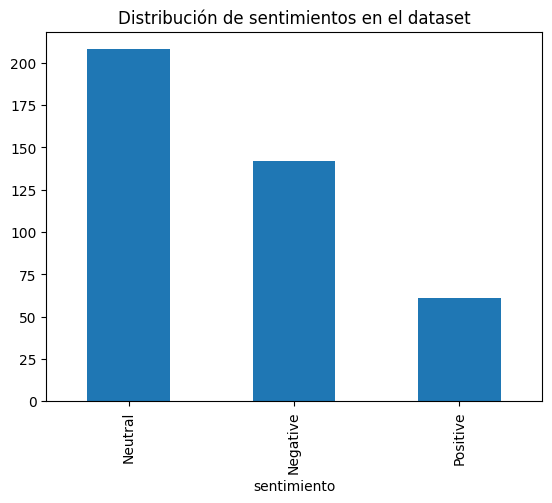

In [8]:
print("Distribución de las categorías de sentimiento:")
conteo_sentimientos = df["sentimiento"].value_counts()
display(conteo_sentimientos)

conteo_sentimientos.plot(
    kind="bar",
    title="Distribución de sentimientos en el dataset"
);


### 3.3 Conversión de las etiquetas

Los modelos de clasificación trabajan internamente con identificadores
numéricos para representar cada categoría.

Por ello, asignaremos un número entero a cada sentimiento y crearemos
también la relación inversa para poder interpretar posteriormente las
predicciones del modelo.

In [9]:
# Las categorías reales del dataset son: Negative, Neutral y Positive.
label2id = {
    "Negative": 0,
    "Neutral": 1,
    "Positive": 2
}

id2label = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

df["label"] = df["sentimiento"].map(label2id)

print("Mapa de etiquetas:", label2id)
df[["texto", "sentimiento", "label"]].head()


Mapa de etiquetas: {'Negative': 0, 'Neutral': 1, 'Positive': 2}


,texto,sentimiento,label
0,Recorriendo el #CampNou🏟 https://t.co/ZKZ1ERaiZS,Neutral,1
1,@FCBarcelona fera desde pequeno😲😲,Neutral,1
2,@sport Y el barca que haria sin Messi????? Ni ...,Negative,0
3,Please RT!! #barcelona #fcbarcelona #Barca #fc...,Neutral,1
4,"@NostradamusFCB Si parce que miedo, sólo el ba...",Neutral,1


### 3.4 Selección de los datos para el entrenamiento

El archivo `train.csv` contiene **411 registros**, por lo que no es necesario reducirlo a una muestra más pequeña.

Utilizaremos todos los registros disponibles después de la limpieza. Esto mantiene el laboratorio manejable en Google Colab y, al mismo tiempo, aprovecha toda la información etiquetada disponible.


In [10]:
df_muestra = df.copy()

print("Registros que se utilizarán:", len(df_muestra))
display(df_muestra["sentimiento"].value_counts())


Registros que se utilizarán: 411


,count
sentimiento,
Neutral,208
Negative,142
Positive,61


### 3.5 División en entrenamiento y evaluación

Dividiremos la muestra en dos conjuntos:

- **Entrenamiento:** datos utilizados para ajustar la cabeza de clasificación.
- **Evaluación:** datos que el modelo no utilizará durante el entrenamiento
  y que permitirán medir su desempeño.

Utilizaremos `stratify` para conservar aproximadamente la misma
proporción de categorías en ambos conjuntos.

In [11]:
train_df, eval_df = train_test_split(
    df_muestra,
    test_size=0.20,
    stratify=df_muestra["label"],
    random_state=42
)

train_df = train_df.reset_index(drop=True)
eval_df = eval_df.reset_index(drop=True)

print("Entrenamiento:", len(train_df))
print("Evaluación:", len(eval_df))
print()
print("Distribución en entrenamiento:")
display(train_df["sentimiento"].value_counts())
print()
print("Distribución en evaluación:")
display(eval_df["sentimiento"].value_counts())


Entrenamiento: 328
Evaluación: 83

Distribución en entrenamiento:


,count
sentimiento,
Neutral,166
Negative,113
Positive,49



Distribución en evaluación:


,count
sentimiento,
Neutral,42
Negative,29
Positive,12


## 4. Configuración de BERT

En esta sección utilizaremos `bert-base-multilingual-cased` como modelo base para la tarea de clasificación.

BERT es un modelo de lenguaje preentrenado que ya ha aprendido representaciones del lenguaje a partir de grandes cantidades de texto.

Utilizaremos su tokenizador correspondiente para transformar los textos del dataset al formato numérico que el modelo necesita para procesarlos.

### 4.1 Selección del modelo base

El modelo seleccionado para este laboratorio será `bert-base-multilingual-cased`.

Se trata de una versión multilingüe de BERT, por lo que puede procesar texto en distintos idiomas y distingue entre mayúsculas y minúsculas.

In [12]:
MODEL_NAME = "bert-base-multilingual-cased"
print("Modelo seleccionado:", MODEL_NAME)


Modelo seleccionado: bert-base-multilingual-cased


### 4.2 Carga del tokenizador

Antes de enviar los textos al modelo, necesitamos convertirlos en una representación numérica.

El tokenizador de BERT divide el texto en unidades llamadas tokens y las transforma en identificadores que pueden ser interpretados por el modelo.

In [13]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print("Tokenizador cargado correctamente.")


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

Tokenizador cargado correctamente.


### 4.3 Tokenización del dataset

Aplicaremos el tokenizador a los textos de los conjuntos de entrenamiento y evaluación.

Durante este proceso utilizaremos:

- `truncation=True` para recortar textos que superen la longitud máxima.
- `padding` para mantener una longitud uniforme entre los ejemplos.
- Una longitud máxima adecuada para los mensajes del dataset.

El resultado de la tokenización incluirá elementos como `input_ids` y `attention_mask`, que serán utilizados posteriormente por BERT.

In [14]:
def tokenizar(batch):
    return tokenizer(
        batch["texto"],
        truncation=True,
        padding="max_length",
        max_length=128
    )


### 4.4 Conversión al formato de Hugging Face

Finalmente, convertiremos los conjuntos de entrenamiento y evaluación al formato `Dataset` de Hugging Face.

Esto permitirá utilizarlos directamente con las herramientas de entrenamiento de la librería `transformers`.

In [15]:
# Convertir los DataFrames a Dataset de Hugging Face
train_dataset = Dataset.from_pandas(
    train_df[["texto", "label"]],
    preserve_index=False
)

eval_dataset = Dataset.from_pandas(
    eval_df[["texto", "label"]],
    preserve_index=False
)

# Tokenizar y eliminar únicamente la columna de texto original.
# NO usamos set_format("torch"): Trainer convierte los batches a tensores automáticamente.
train_dataset = train_dataset.map(
    tokenizar,
    batched=True,
    remove_columns=["texto"]
)

eval_dataset = eval_dataset.map(
    tokenizar,
    batched=True,
    remove_columns=["texto"]
)

print("Dataset de entrenamiento:")
print(train_dataset)
print("\nDataset de evaluación:")
print(eval_dataset)

# Comprobación sencilla sin forzar formato Torch
ejemplo = train_dataset[0]
print("\nClaves del primer ejemplo tokenizado:", ejemplo.keys())
print("Label:", ejemplo["label"])
print("Primeros 12 input_ids:", ejemplo["input_ids"][:12])
print("Primeros 12 attention_mask:", ejemplo["attention_mask"][:12])


Map:   0%|          | 0/328 [00:00<?, ? examples/s]

Map:   0%|          | 0/83 [00:00<?, ? examples/s]

Dataset de entrenamiento:
Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 328
})

Dataset de evaluación:
Dataset({
    features: ['label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 83
})

Claves del primer ejemplo tokenizado: dict_keys(['label', 'input_ids', 'token_type_ids', 'attention_mask'])
Label: 1
Primeros 12 input_ids: [101, 100, 19472, 20461, 10129, 131, 107, 37312, 23964, 15699, 10192, 12832]
Primeros 12 attention_mask: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]


## 5. Transfer Learning y congelado de capas

En esta sección adaptaremos el modelo BERT preentrenado a nuestra tarea de clasificación de sentimiento.

En lugar de entrenar todos los parámetros del modelo, utilizaremos Transfer Learning para aprovechar el conocimiento que BERT ya adquirió durante su preentrenamiento.

Para ello, congelaremos las capas base del modelo y dejaremos entrenable únicamente la cabeza de clasificación.

### 5.1 Carga del modelo para clasificación

Cargaremos BERT como un modelo de clasificación de secuencias.

La capa final será configurada de acuerdo con el número de categorías de sentimiento presentes en nuestro dataset.

In [16]:
num_labels = len(label2id)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id
)

print("Número de categorías:", num_labels)


model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Número de categorías: 3


### 5.2 Congelado de las capas base

Para evitar modificar el conocimiento previamente aprendido por BERT, desactivaremos el entrenamiento de sus capas base utilizando `requires_grad = False`.

De esta manera, durante el entrenamiento solamente se actualizarán los parámetros correspondientes a la cabeza de clasificación.

In [17]:
# Congelar las capas base de BERT.
# La cabeza de clasificación permanece entrenable.
for param in model.base_model.parameters():
    param.requires_grad = False

print("Capas base de BERT congeladas.")


Capas base de BERT congeladas.


### 5.3 Verificación de parámetros entrenables

Después de congelar las capas base, comprobaremos cuántos parámetros posee el modelo y cuántos permanecen entrenables.

Esta verificación nos permitirá confirmar que el congelado de capas se aplicó correctamente.

In [18]:
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Parámetros totales: {total_params:,}")
print(f"Parámetros entrenables: {trainable_params:,}")
print(f"Porcentaje entrenable: {100 * trainable_params / total_params:.4f}%")

print("\nCapas que permanecen entrenables:")
for nombre, parametro in model.named_parameters():
    if parametro.requires_grad:
        print("-", nombre)


Parámetros totales: 177,855,747
Parámetros entrenables: 2,307
Porcentaje entrenable: 0.0013%

Capas que permanecen entrenables:
- classifier.weight
- classifier.bias


## 6. Configuración del entrenamiento

En esta sección definiremos cómo se realizará el entrenamiento de la cabeza de clasificación.

Configuraremos aspectos como el número de épocas, el tamaño de los batches y la estrategia de evaluación utilizando `TrainingArguments`.

### 6.1 Métrica de evaluación

Utilizaremos una métrica de clasificación para medir el desempeño del modelo durante la evaluación.

En este laboratorio utilizaremos `accuracy`, que representa la proporción de predicciones correctas realizadas por el modelo.

In [19]:
metrica_accuracy = evaluate.load("accuracy")

def calcular_metricas(eval_pred):
    logits, labels = eval_pred
    predicciones = np.argmax(logits, axis=-1)

    return metrica_accuracy.compute(
        predictions=predicciones,
        references=labels
    )


### 6.2 Parámetros de entrenamiento

Definiremos los principales parámetros que controlarán el proceso de entrenamiento.

Entre ellos se encuentran:

- Número de épocas.
- Tamaño del batch de entrenamiento.
- Tamaño del batch de evaluación.
- Estrategia de evaluación.
- Directorio donde se almacenarán los resultados.

In [20]:
argumentos_entrenamiento = TrainingArguments(
    output_dir="./resultados_bert_futbol",
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    learning_rate=2e-5,
    eval_strategy="epoch",
    save_strategy="no",
    logging_strategy="epoch",
    report_to="none",
    seed=42
)


## 7. Entrenamiento del modelo

Utilizaremos la clase `Trainer` de Hugging Face para realizar el entrenamiento.

El `Trainer` conectará el modelo, los datasets tokenizados, los parámetros de entrenamiento y la función utilizada para calcular las métricas.

Debido al congelado realizado anteriormente, solamente la cabeza de clasificación será actualizada durante este proceso.

### 7.1 Creación del Trainer

Configuraremos el objeto `Trainer` utilizando:

- El modelo de clasificación.
- El conjunto de entrenamiento.
- El conjunto de evaluación.
- Los argumentos de entrenamiento.
- La función utilizada para calcular las métricas.

In [21]:
trainer = Trainer(
    model=model,
    args=argumentos_entrenamiento,
    train_dataset=train_dataset,
    eval_dataset=eval_dataset,
    compute_metrics=calcular_metricas,
    processing_class=tokenizer
)

print("Trainer configurado correctamente.")


Trainer configurado correctamente.


### 7.2 Ejecución del entrenamiento

Finalmente, iniciaremos el proceso de entrenamiento.

Durante esta etapa el modelo aprenderá a relacionar las representaciones generadas por BERT con las diferentes categorías de sentimiento del dataset.

In [22]:
resultado_entrenamiento = trainer.train()
resultado_entrenamiento


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy
1,1.078834,1.071403,0.361446
2,1.069312,1.062770,0.385542
3,1.060306,1.059963,0.433735


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


TrainOutput(global_step=123, training_loss=1.069484152444979, metrics={'train_runtime': 635.1451, 'train_samples_per_second': 1.549, 'train_steps_per_second': 0.194, 'total_flos': 64725900761088.0, 'train_loss': 1.069484152444979, 'epoch': 3.0})

## 8. Evaluación del modelo

Una vez terminado el entrenamiento, evaluaremos el modelo utilizando el conjunto de datos reservado para evaluación.

Estos textos no serán utilizados para ajustar el modelo, por lo que nos permitirán observar qué tan bien puede clasificar ejemplos diferentes a los utilizados durante el entrenamiento.

### 8.1 Resultados de evaluación

Mostraremos las métricas obtenidas durante la evaluación, incluyendo el valor de `accuracy` y la pérdida del modelo.

Estos resultados nos permitirán analizar el desempeño alcanzado después del entrenamiento.

In [23]:
resultados = trainer.evaluate()

print("Resultados de evaluación:")
for clave, valor in resultados.items():
    if isinstance(valor, float):
        print(f"{clave}: {valor:.4f}")
    else:
        print(f"{clave}: {valor}")


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy
1.060306,1.059963,3,0.433735


Resultados de evaluación:
eval_loss: 1.0600
eval_accuracy: 0.4337


## 9. Inferencia con textos nuevos

Después de entrenar y evaluar el modelo, realizaremos predicciones utilizando textos nuevos relacionados con fútbol.

Cada texto será tokenizado y enviado al modelo para obtener las probabilidades asociadas a cada categoría de sentimiento.

### 9.1 Predicción de una frase nueva

Utilizaremos una frase que no haya participado en el entrenamiento para comprobar cómo responde el modelo ante un ejemplo nuevo.

La salida mostrará:

- La frase analizada.
- La categoría de sentimiento predicha.
- El puntaje de confianza asociado a la predicción.

In [24]:
def predecir_sentimiento(texto, modelo=model, tokenizador=tokenizer):
    modelo.eval()

    encoding = tokenizador(
        texto,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    encoding = {k: v.to(modelo.device) for k, v in encoding.items()}

    with torch.no_grad():
        outputs = modelo(**encoding)

    probabilidades = torch.softmax(outputs.logits, dim=-1)
    clase_id = torch.argmax(probabilidades, dim=-1).item()
    score = probabilidades[0][clase_id].item()
    categoria = modelo.config.id2label[clase_id]

    return categoria, score

frase_nueva = "What an incredible goal! This match has been amazing."
categoria, score = predecir_sentimiento(frase_nueva)

print("Frase:", frase_nueva)
print("Categoría ganadora:", categoria)
print(f"Puntaje de confianza: {score:.4f} ({score * 100:.2f}%)")


Frase: What an incredible goal! This match has been amazing.
Categoría ganadora: Negative
Puntaje de confianza: 0.3818 (38.18%)


### 9.2 Pruebas adicionales

Además de la inferencia principal, utilizaremos algunas frases adicionales con diferentes tipos de sentimiento para observar el comportamiento del modelo.

Estas pruebas permitirán comparar cómo clasifica expresiones positivas, negativas y otras categorías disponibles en el dataset.

In [25]:
frases_prueba = [
    "¡Qué partidazo! El equipo jugó increíble y ese gol fue espectacular.",
    "Qué desastre de partido, jugaron muy mal y perdieron otra vez.",
    "El partido terminó después de noventa minutos de juego."
]

for frase in frases_prueba:
    categoria, score = predecir_sentimiento(frase)
    print("Texto:", frase)
    print("Categoría ganadora:", categoria)
    print(f"Confianza: {score:.2%}")
    print("-" * 70)


Texto: ¡Qué partidazo! El equipo jugó increíble y ese gol fue espectacular.
Categoría ganadora: Negative
Confianza: 35.20%
----------------------------------------------------------------------
Texto: Qué desastre de partido, jugaron muy mal y perdieron otra vez.
Categoría ganadora: Negative
Confianza: 35.92%
----------------------------------------------------------------------
Texto: El partido terminó después de noventa minutos de juego.
Categoría ganadora: Neutral
Confianza: 38.24%
----------------------------------------------------------------------


## 10. Conclusiones

En este laboratorio se aplicó Transfer Learning utilizando `bert-base-multilingual-cased` para una tarea de clasificación de sentimiento en mensajes relacionados con fútbol.

Las capas base de BERT fueron congeladas mediante `requires_grad = False`, por lo que sus parámetros no se actualizan durante el entrenamiento. De esta manera se reutilizan las representaciones lingüísticas aprendidas previamente por BERT y se entrena únicamente la cabeza de clasificación para distinguir entre las categorías **Negative**, **Neutral** y **Positive**.

El desempeño final debe interpretarse a partir de las métricas obtenidas al ejecutar las secciones de entrenamiento y evaluación. Finalmente, el modelo se prueba con textos nuevos para mostrar la categoría predicha y su puntaje de confianza.
